# Discrete-Time Signal Processing: Activity 2
## Operation of Sequence

This notebook covers scalar addition, scalar multiplication, time shift (delay), and time advance on a discrete-time sequence.

## Dependencies
Run the cell below once to install the required packages.

In [9]:
# Run this once if numpy/matplotlib are not yet installed
!pip install numpy matplotlib

In [10]:
import numpy as np
import matplotlib.pyplot as plt

## Base Sequence

In [11]:
n = np.arange(-5, 6)
x = np.array([0, 5, 6, 7, 9, 0, 0, -5, -9, -7, -6])
print(n)
print(x)

[-5 -4 -3 -2 -1  0  1  2  3  4  5]
[ 0  5  6  7  9  0  0 -5 -9 -7 -6]


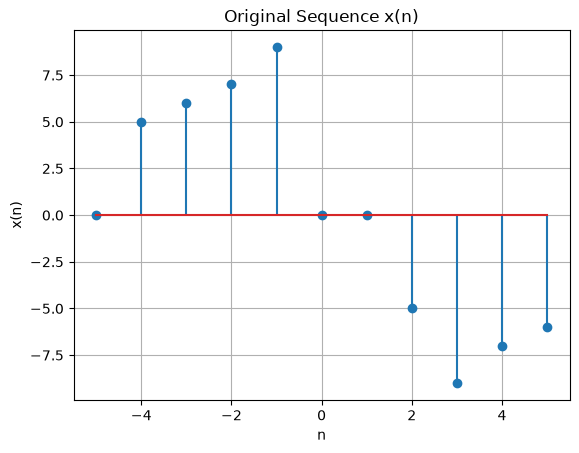

In [12]:
plt.stem(n, x)
plt.title('Original Sequence x(n)')
plt.xlabel('n')
plt.ylabel('x(n)')
plt.grid(True)
plt.show()

### 1. Scalar Addition: y(n) = x(n) + A

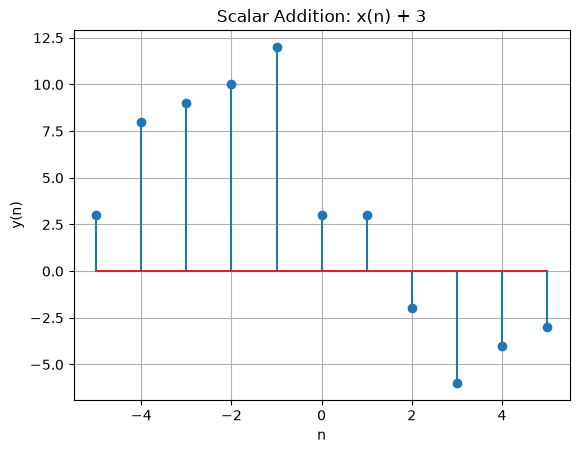

In [13]:
A = 3
y_add = x + A

plt.stem(n, y_add)
plt.title(f'Scalar Addition: x(n) + {A}')
plt.xlabel('n')
plt.ylabel('y(n)')
plt.grid(True)
plt.show()

### 2. Scalar Multiplication: y(n) = A * x(n)

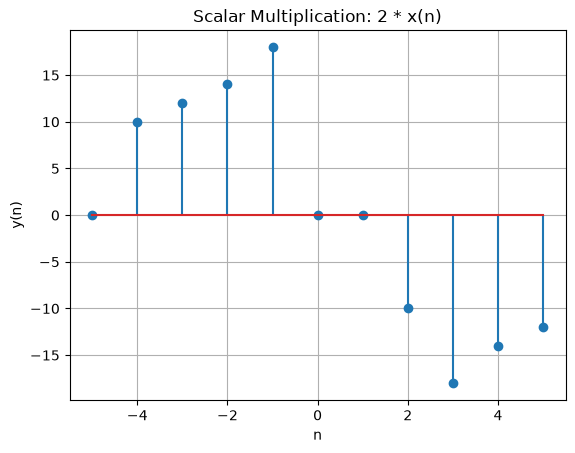

In [14]:
A = 2
y_mult = A * x

plt.stem(n, y_mult)
plt.title(f'Scalar Multiplication: {A} * x(n)')
plt.xlabel('n')
plt.ylabel('y(n)')
plt.grid(True)
plt.show()

### 3. Time Shift (Delay): y(n) = x(n - k)

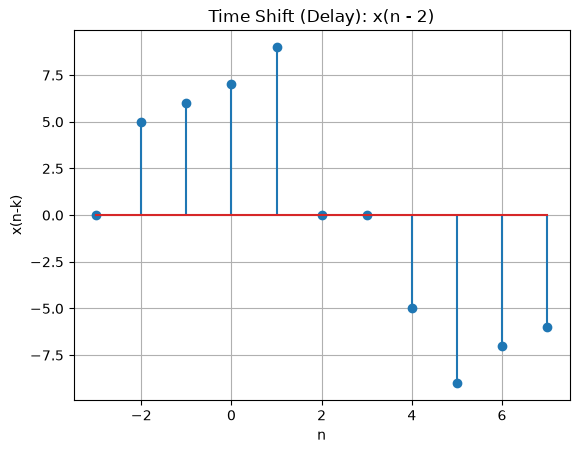

In [15]:
k = 2
n_shifted = n + k  # shifting the n-axis to the right represents a delay

plt.stem(n_shifted, x)
plt.title(f'Time Shift (Delay): x(n - {k})')
plt.xlabel('n')
plt.ylabel('x(n-k)')
plt.grid(True)
plt.show()

### 4. Time Advance: y(n) = x(n + k)

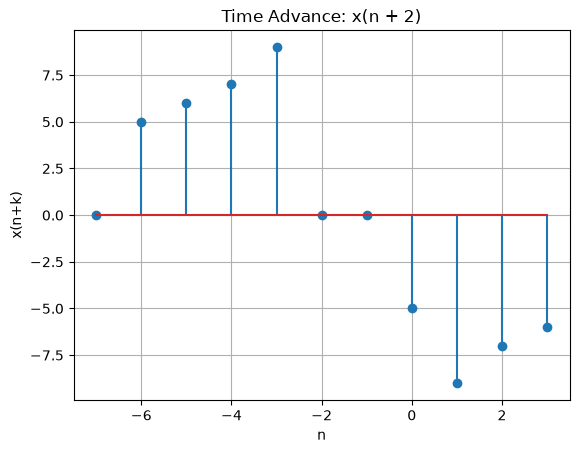

In [16]:
k = 2
n_advanced = n - k  # shifting the n-axis to the left represents an advance

plt.stem(n_advanced, x)
plt.title(f'Time Advance: x(n + {k})')
plt.xlabel('n')
plt.ylabel('x(n+k)')
plt.grid(True)
plt.show()

### 5. Time Reversal (Folding): y(n) = x(-n)

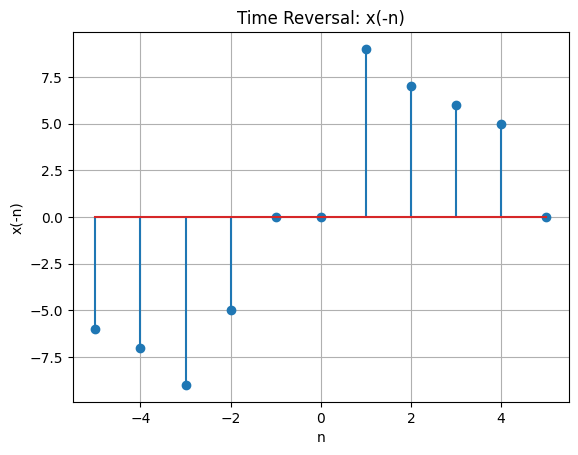

In [17]:
n_rev = -n  # folding reflects the n-axis about n = 0

plt.stem(n_rev, x)
plt.title('Time Reversal: x(-n)')
plt.xlabel('n')
plt.ylabel('x(-n)')
plt.grid(True)
plt.show()

### 6. Composite Method 1 (Shift then Fold): y(n) = x(-n + k)

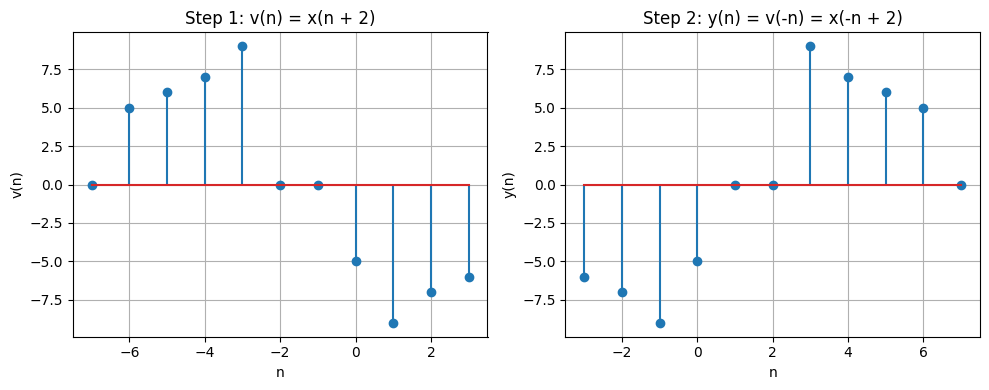

In [18]:
k = 2
n_v1 = n - k   # step 1: v(n) = x(n + k), shift left by k
n_y1 = -n_v1   # step 2: y(n) = v(-n), fold -> n_y = k - n

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].stem(n_v1, x)
ax[0].set_title(f'Step 1: v(n) = x(n + {k})')
ax[0].set_xlabel('n')
ax[0].set_ylabel('v(n)')
ax[0].grid(True)

ax[1].stem(n_y1, x)
ax[1].set_title(f'Step 2: y(n) = v(-n) = x(-n + {k})')
ax[1].set_xlabel('n')
ax[1].set_ylabel('y(n)')
ax[1].grid(True)

plt.tight_layout()
plt.show()

### 7. Composite Method 2 (Fold then Shift): y(n) = x(-n + k)

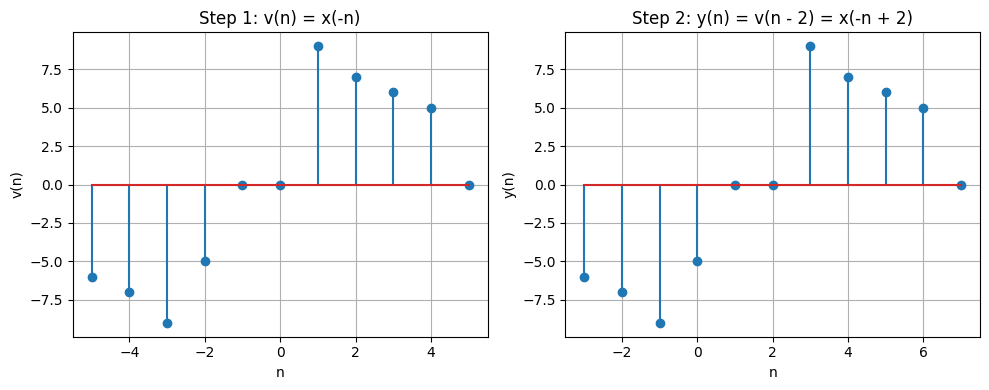

Method 1 and Method 2 give the same result: True


In [19]:
k = 2
n_v2 = -n        # step 1: v(n) = x(-n), fold
n_y2 = n_v2 + k  # step 2: y(n) = v(n - k), delay by k -> n_y = k - n

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].stem(n_v2, x)
ax[0].set_title('Step 1: v(n) = x(-n)')
ax[0].set_xlabel('n')
ax[0].set_ylabel('v(n)')
ax[0].grid(True)

ax[1].stem(n_y2, x)
ax[1].set_title(f'Step 2: y(n) = v(n - {k}) = x(-n + {k})')
ax[1].set_xlabel('n')
ax[1].set_ylabel('y(n)')
ax[1].grid(True)

plt.tight_layout()
plt.show()

print('Method 1 and Method 2 give the same result:', np.array_equal(n_y1, n_y2))

### 8. Sample-Wise Signal Addition: y(n) = x1(n) + x2(n)

[-1  0  1  2]
[1 2 3 0]
[0 4 5 6]
[1 6 8 6]


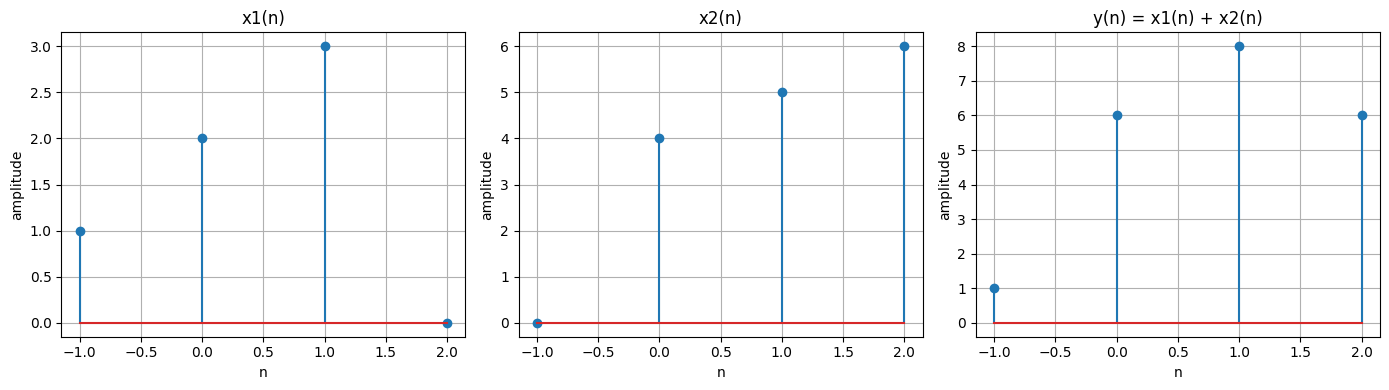

In [20]:
n1 = np.array([-1, 0, 1])
x1 = np.array([1, 2, 3])
n2 = np.array([0, 1, 2])
x2 = np.array([4, 5, 6])

# common index range; positions with no sample default to zero
n_s = np.arange(min(n1.min(), n2.min()), max(n1.max(), n2.max()) + 1)
x1_s = np.array([x1[n1 == i][0] if i in n1 else 0 for i in n_s])
x2_s = np.array([x2[n2 == i][0] if i in n2 else 0 for i in n_s])

y_sum = x1_s + x2_s
print(n_s)
print(x1_s)
print(x2_s)
print(y_sum)

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, sig, title in zip(ax, [x1_s, x2_s, y_sum], ['x1(n)', 'x2(n)', 'y(n) = x1(n) + x2(n)']):
    a.stem(n_s, sig)
    a.set_title(title)
    a.set_xlabel('n')
    a.set_ylabel('amplitude')
    a.grid(True)
plt.tight_layout()
plt.show()

### 9. Sample-Wise Signal Multiplication: y(n) = x1(n) * x2(n)

[-1  0  1  2]
[ 0  8 15  0]


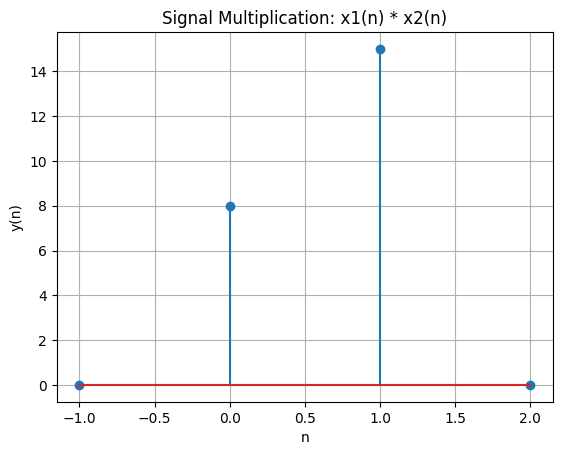

In [21]:
y_prod = x1_s * x2_s
print(n_s)
print(y_prod)

plt.stem(n_s, y_prod)
plt.title('Signal Multiplication: x1(n) * x2(n)')
plt.xlabel('n')
plt.ylabel('y(n)')
plt.grid(True)
plt.show()